# Laboratorio Clase 9: un agente con trazas en LangSmith

**Módulo II: Navegando por los componentes de la IA. Sesión 9, 19 de noviembre de 2026**

En la clase 8 vimos cuándo conviene un agente. Hoy construimos uno para una tarea real de cadena de suministro y lo hacemos observable: cada llamada al modelo y cada herramienta queda registrada como una traza en LangSmith. Sin trazas, un agente es una caja negra; con trazas, puedes auditar qué vio, qué decidió y cuánto costó.

| Misión | Qué vas a hacer | Concepto de la clase |
|---|---|---|
| 1 | Definir herramientas trazables y una política de compras | Herramientas como contrato, política en código |
| 2 | Construir el agente y leer su traza | Loop ReAct, salida estándar, observabilidad |
| 3 | Probar los modos SIMULATE, SAFE y LIVE | Efectos secundarios controlados e idempotencia |
| 4 | Medir el uso de tokens y la caché | Costo por traza y *prompt caching* |
| 5 | Evaluar el agente con un set mínimo de casos | Métricas y decisión *go/no-go* |

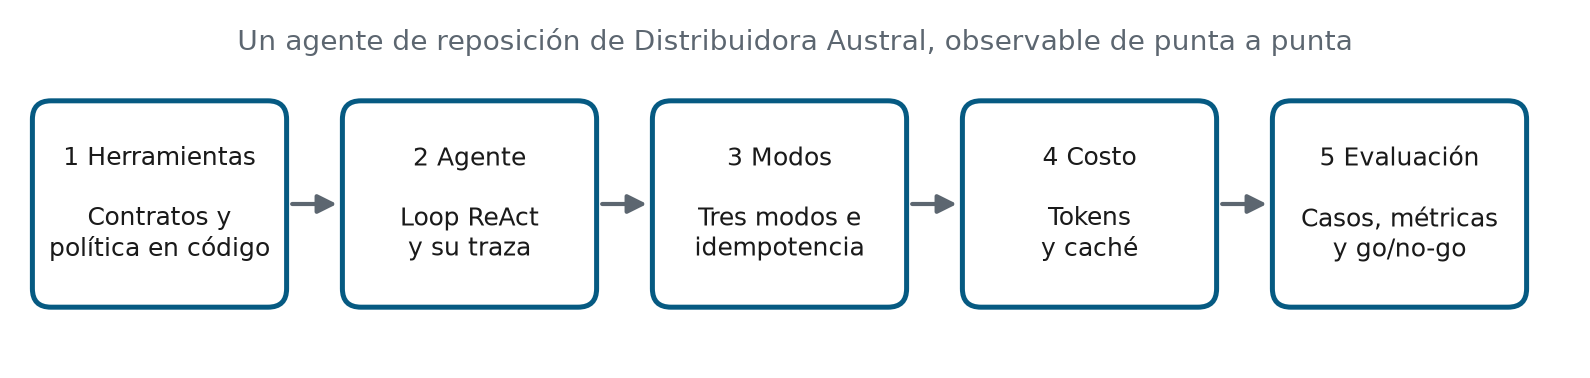

ReAct significa *Reason + Act*: el modelo razona, llama una herramienta, observa el resultado y repite. Una **traza** es el árbol de pasos de una ejecución: la cadena principal, cada llamada al LLM (*large language model*) y cada herramienta, con sus entradas, salidas, latencia y tokens.

### Cómo usar este notebook

Ejecuta cada celda con **Shift + Enter**. Lee el resultado antes de seguir. Si algo falla, usa **Kernel, Restart y Run All**. No necesitas entender cada línea: lee los comentarios que empiezan con `#`.

Cada misión termina con una pregunta **Para la puesta en común**. Anota tu respuesta: la conversamos al final.

## Paso 0: revisar el ambiente

Este laboratorio tiene su propio ambiente virtual en la carpeta `clase_09-langsmith/.venv`. Se crea con `uv sync`. Copia `env.example` como `.env` y completa dos claves:

1. `ANTHROPIC_API_KEY`: la clave de la API de Claude.
2. `LANGSMITH_API_KEY`: la clave de LangSmith. Se crea gratis en [smith.langchain.com](https://smith.langchain.com), en **Settings, API Keys**.

Sin la clave de Claude, el notebook usa un cliente simulado. Sin la clave de LangSmith, el agente funciona igual, pero no envía trazas.

In [1]:
# Paso 0: importar las herramientas y buscar las claves
import importlib.util
import subprocess
import sys

if "google.colab" in sys.modules and importlib.util.find_spec("langsmith") is None:
    subprocess.run(["uv", "pip", "install", "--system", "-q", "anthropic", "langsmith"], check=True)  # Colab no trae estos paquetes

import json
import os
import re
import time
import uuid
from pathlib import Path
from types import SimpleNamespace
from typing import Literal

import anthropic
from pydantic import BaseModel, Field, ValidationError

USAR_CLAUDE = True  # cambia a False para usar el modo simulado
MODELO = "claude-haiku-5-5"

def cargar_env():
    try:
        from dotenv import load_dotenv
    except ImportError:   # por ejemplo, en Colab
        return False
    aqui = Path.cwd().resolve()
    for carpeta in [aqui, *list(aqui.parents)[:5]]:
        env = carpeta / ".env"
        if env.is_file():
            load_dotenv(env)
            return True
    return False

cargar_env()
if not os.environ.get("LANGSMITH_API_KEY"):
    os.environ["LANGSMITH_TRACING"] = "false"   # sin clave de LangSmith no hay a dónde enviar trazas

# LangSmith se importa después de leer el .env: así toma LANGSMITH_TRACING y LANGSMITH_PROJECT
from langsmith import Client, evaluate, traceable
from langsmith.run_trees import get_cached_client
from langsmith.utils import LangSmithNotFoundError, tracing_is_enabled
from langsmith.wrappers import wrap_anthropic

hay_clave = USAR_CLAUDE and bool(os.environ.get("ANTHROPIC_API_KEY"))
print("Modelo:", "Claude Haiku 5.5 por API" if hay_clave else "simulado (sin clave de API)")
print("Trazas:", f"activas, proyecto '{os.environ.get('LANGSMITH_PROJECT', 'default')}'" if tracing_is_enabled() else "apagadas")

Modelo: Claude Haiku 5.5 por API
Trazas: activas, proyecto 'clase-09-agentes'


### Los datos: Distribuidora Austral

Distribuidora Austral abastece almacenes del sur de Chile. Cada mañana un analista revisa el inventario y crea órdenes de compra. Queremos que un agente haga ese trabajo, bajo una política de compras. Estos datos son ficticios.

El **catálogo** cambia poco: va en el prompt de sistema y se guarda en caché. El **inventario** cambia todo el día: el agente lo consulta con una herramienta.

In [2]:
# Paso 0b: proveedores, catálogo e inventario
PROVEEDORES = {
    "PR-01": {"nombre": "Agrícola Sur", "estado": "activo", "motivo": ""},
    "PR-02": {"nombre": "Lácteos del Lago", "estado": "activo", "motivo": ""},
    "PR-03": {"nombre": "Comercial Fiordos", "estado": "activo", "motivo": ""},
    "PR-09": {"nombre": "Importadora Pacífico", "estado": "bloqueado", "motivo": "tres entregas incompletas en 2026"},
}

FAMILIAS = ["Aceite", "Arroz", "Harina", "Azúcar", "Fideos", "Avena", "Lentejas", "Sal", "Detergente", "Papel higiénico"]

# 100 productos generados con una fórmula fija, más cuatro productos para los casos de prueba
CATALOGO = {
    f"SKU-{i:03d}": {"nombre": f"{FAMILIAS[i % 10]} formato {i // 10 + 1}", "proveedor": f"PR-0{i % 3 + 1}",
                     "precio": 800 + 45 * i, "lead_time": 2 + i % 4}
    for i in range(100)
}
CATALOGO = CATALOGO | {
    "SKU-900": {"nombre": "Aceite maravilla 1 L", "proveedor": "PR-01", "precio": 2_500, "lead_time": 3},
    "SKU-901": {"nombre": "Café en grano 1 kg", "proveedor": "PR-09", "precio": 9_000, "lead_time": 10},
    "SKU-902": {"nombre": "Leche entera 1 L", "proveedor": "PR-02", "precio": 1_100, "lead_time": 2},
    "SKU-903": {"nombre": "Arroz grado 1, 1 kg", "proveedor": "PR-03", "precio": 1_300, "lead_time": 4},
}

INVENTARIO = {sku: {"stock": 300 + (i * 37) % 500, "consumo_diario": 5 + (i * 13) % 40} for i, sku in enumerate(CATALOGO)}
INVENTARIO = INVENTARIO | {
    "SKU-900": {"stock": 40, "consumo_diario": 30},
    "SKU-901": {"stock": 20, "consumo_diario": 10},
    "SKU-902": {"stock": 200, "consumo_diario": 150},
    "SKU-903": {"stock": 3_000, "consumo_diario": 20},
}

def pesos(monto):
    return f"${monto:,}".replace(",", ".")

print(f"{len(CATALOGO)} productos. Ejemplo: SKU-900 =", CATALOGO["SKU-900"], INVENTARIO["SKU-900"])

104 productos. Ejemplo: SKU-900 = {'nombre': 'Aceite maravilla 1 L', 'proveedor': 'PR-01', 'precio': 2500, 'lead_time': 3} {'stock': 40, 'consumo_diario': 30}


---

## Misión 1: herramientas trazables y política de compras

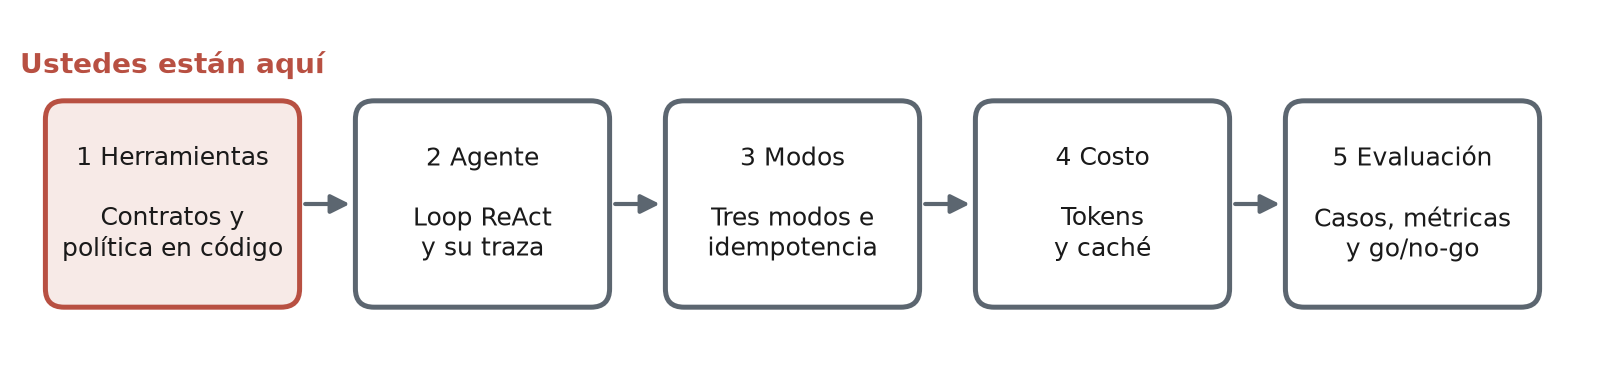

Una herramienta es una función de Python con un contrato: nombre, descripción y parámetros. El decorador `@traceable(run_type="tool")` de LangSmith registra cada llamada como un paso de la traza, con su entrada, su salida y su duración.

Dos reglas de diseño de la clase:

1. **La aritmética la hace el código, no el modelo.** `calcular_reposicion` calcula la cantidad sugerida; el modelo solo la usa.
2. **La política vive en el código.** `revisar_politica` decide qué se puede comprar. El prompt la explica, pero el código la impone.

Las tres herramientas de lectura no cambian nada en el mundo: se pueden llamar mil veces sin riesgo. La única herramienta que escribe es `crear_orden_compra`, y por eso pasa siempre por la política.

In [3]:
# Misión 1a: tres herramientas de lectura, sin efectos secundarios
HORIZONTE_DIAS = 14

@traceable(run_type="tool")
def consultar_inventario(sku):
    item = INVENTARIO[sku]
    return {"sku": sku, "stock": item["stock"], "consumo_diario": item["consumo_diario"],
            "dias_cobertura": round(item["stock"] / item["consumo_diario"], 1)}

@traceable(run_type="tool")
def calcular_reposicion(sku, horizonte_dias):
    dias = horizonte_dias + CATALOGO[sku]["lead_time"]   # cubrir el horizonte más lo que tarda el proveedor
    cantidad = max(0, INVENTARIO[sku]["consumo_diario"] * dias - INVENTARIO[sku]["stock"])
    return {"sku": sku, "dias_a_cubrir": dias, "cantidad_sugerida": cantidad,
            "monto_estimado": pesos(cantidad * CATALOGO[sku]["precio"])}

@traceable(run_type="tool")
def consultar_proveedor(proveedor_id):
    return {"proveedor_id": proveedor_id, **PROVEEDORES[proveedor_id]}

print(consultar_inventario("SKU-900"))
print(calcular_reposicion("SKU-900", HORIZONTE_DIAS))
print(consultar_proveedor("PR-09"))

{'sku': 'SKU-900', 'stock': 40, 'consumo_diario': 30, 'dias_cobertura': 1.3}
{'sku': 'SKU-900', 'dias_a_cubrir': 17, 'cantidad_sugerida': 470, 'monto_estimado': '$1.175.000'}
{'proveedor_id': 'PR-09', 'nombre': 'Importadora Pacífico', 'estado': 'bloqueado', 'motivo': 'tres entregas incompletas en 2026'}


In [4]:
# Misión 1b: la política de compras y la única herramienta que escribe
MAX_UNIDADES = 5_000
UMBRAL_APROBACION = 2_000_000   # sobre este monto, un comprador humano aprueba (HITL)
MODO = "SAFE"                   # SIMULATE, SAFE o LIVE; lo usamos en la misión 3
ORDENES = {}

def revisar_politica(sku, cantidad):
    proveedor = PROVEEDORES[CATALOGO[sku]["proveedor"]]
    bloqueos = []
    if proveedor["estado"] == "bloqueado":
        bloqueos.append(f"proveedor {proveedor['nombre']} bloqueado por {proveedor['motivo']}")
    if not 0 < cantidad <= MAX_UNIDADES:
        bloqueos.append(f"la cantidad debe estar entre 1 y {MAX_UNIDADES}")
    requiere_aprobacion = cantidad * CATALOGO[sku]["precio"] > UMBRAL_APROBACION
    return bloqueos, requiere_aprobacion

@traceable(run_type="tool")
def crear_orden_compra(sku, cantidad, motivo):
    bloqueos, requiere_aprobacion = revisar_politica(sku, cantidad)
    if bloqueos:
        return "RECHAZADO: " + "; ".join(bloqueos)
    clave = f"{sku}-{cantidad}"   # clave de idempotencia: la misma orden no se crea dos veces
    if clave in ORDENES:
        return f"Sin cambios: la orden {clave} ya existe en estado {ORDENES[clave]['estado']}."
    monto = cantidad * CATALOGO[sku]["precio"]
    if MODO == "SIMULATE":
        return f"SIMULADO: se crearía la orden {clave} por {pesos(monto)}. No se guardó nada."
    estado = "enviada" if MODO == "LIVE" and not requiere_aprobacion else "borrador"
    ORDENES[clave] = {"sku": sku, "cantidad": cantidad, "monto": monto, "estado": estado, "motivo": motivo}
    aviso = " Requiere la aprobación de un comprador." if requiere_aprobacion else ""
    return f"Orden {clave} por {pesos(monto)} en estado {estado}.{aviso}"

### La política como compuerta

Toda orden pasa por `revisar_politica` antes de existir. La compuerta tiene tres salidas:

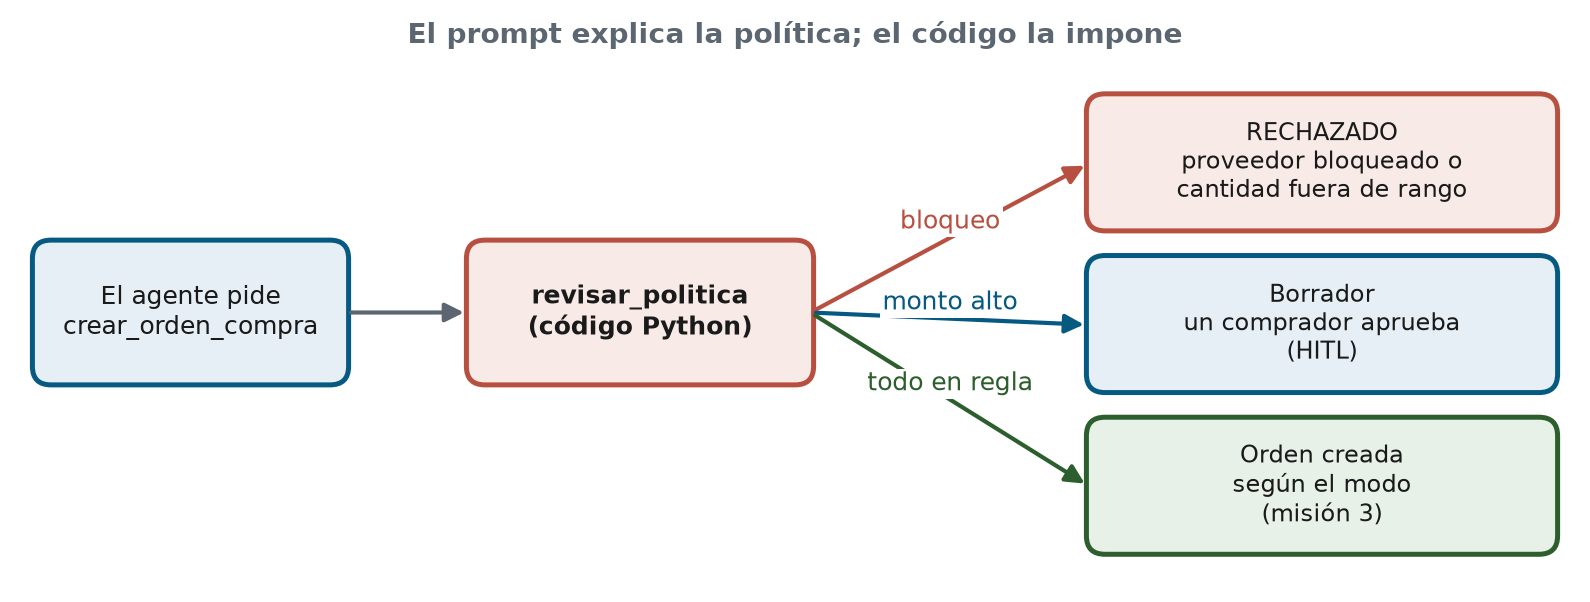

La siguiente celda prueba la compuerta con cinco pedidos, sin agente y sin modelo. Así se prueba una política: con casos fijos y resultados que se pueden verificar a mano.

In [5]:
# Misión 1c: la política frente a cinco pedidos
PRUEBAS = [("SKU-900", 470), ("SKU-901", 220), ("SKU-902", 2_200), ("SKU-900", 0), ("SKU-903", 6_000)]

for sku, cantidad in PRUEBAS:
    bloqueos, requiere_aprobacion = revisar_politica(sku, cantidad)
    if bloqueos:
        veredicto = "BLOQUEADO: " + "; ".join(bloqueos)
    else:
        veredicto = "requiere aprobación" if requiere_aprobacion else "permitido"
    print(f"{sku} x {cantidad:>5} = {pesos(cantidad * CATALOGO[sku]['precio']):>11}  {veredicto}")

SKU-900 x   470 =  $1.175.000  permitido
SKU-901 x   220 =  $1.980.000  BLOQUEADO: proveedor Importadora Pacífico bloqueado por tres entregas incompletas en 2026
SKU-902 x  2200 =  $2.420.000  requiere aprobación
SKU-900 x     0 =          $0  BLOQUEADO: la cantidad debe estar entre 1 y 5000
SKU-903 x  6000 =  $7.800.000  BLOQUEADO: la cantidad debe estar entre 1 y 5000


**Prueba tú:** agrega a `PRUEBAS` un pedido de SKU-902 por 1.800 unidades. Calcula el monto a mano antes de ejecutar. ¿Requiere aprobación?

**Para la puesta en común:** el proveedor PR-09 está bloqueado. ¿Qué pasaría si esa regla estuviera solo en el prompt y no en `revisar_politica`? ¿Qué otra regla de compras de tu empresa pondrías en código?

---

## Misión 2: el agente y su traza

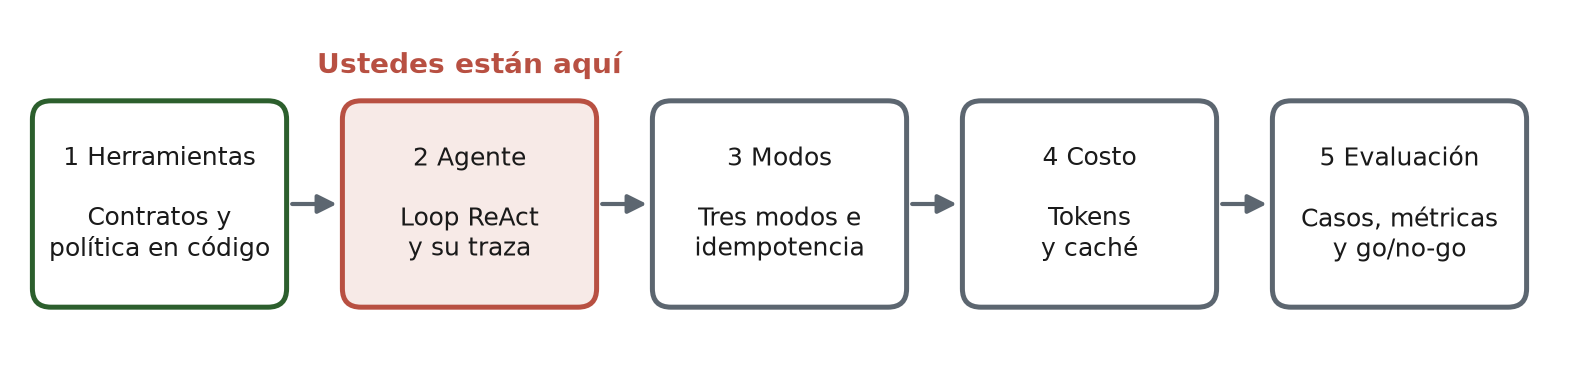

El agente recibe un SKU (*stock keeping unit*, el código de un producto) y decide si reponer. Usa las herramientas de la misión 1 y termina con la herramienta `entregar_respuesta`, que fija una **salida estándar**: respuesta, acción, evidencia, confianza y siguiente paso. Pydantic valida esa salida; si no cumple, el error vuelve al modelo para que la corrija.

Dos piezas de LangSmith hacen visible el loop:

1. `@traceable(run_type="chain")` sobre la función del agente crea la raíz de la traza.
2. `wrap_anthropic(cliente)` registra cada llamada a Claude como un paso de tipo LLM, con tokens y latencia.

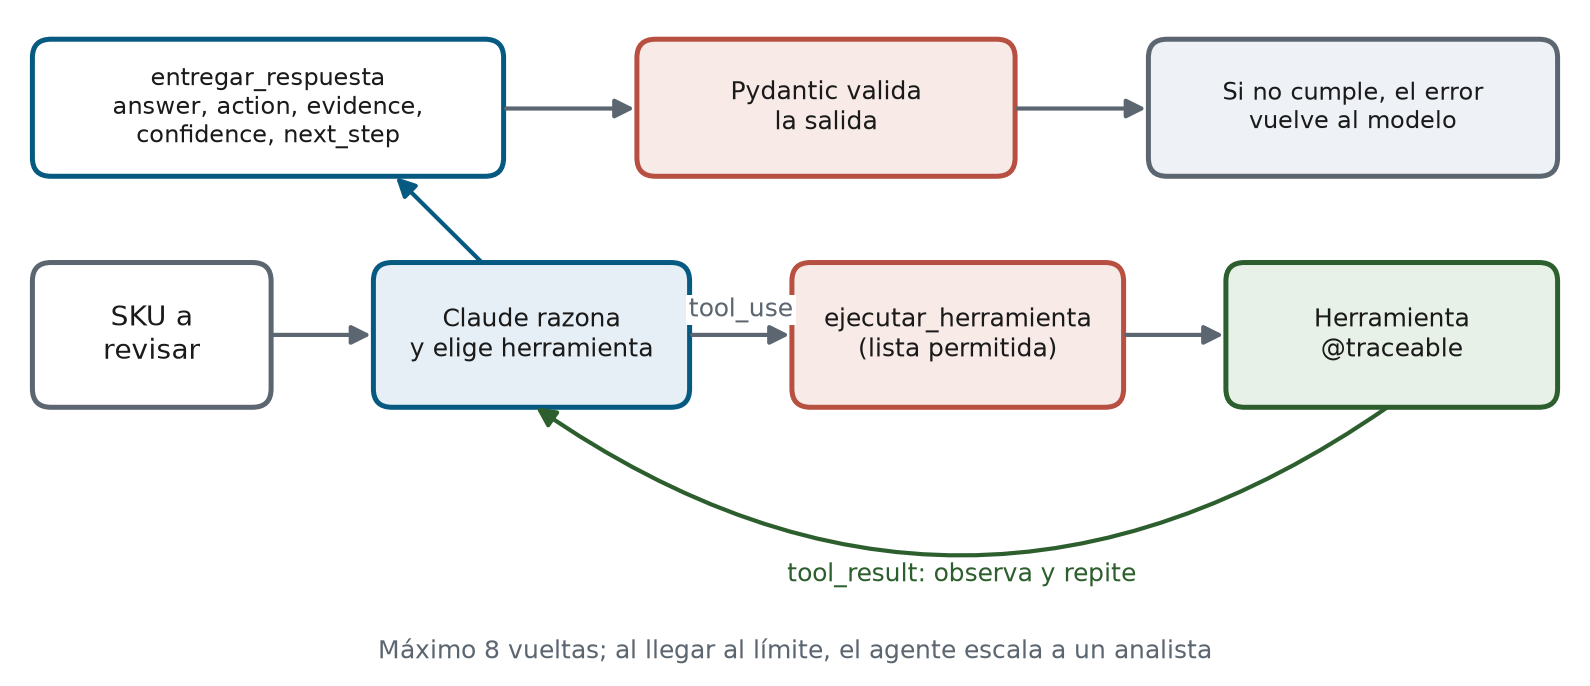

Fíjate en la caja roja: el modelo **pide** una herramienta, pero `ejecutar_herramienta` decide si la ejecuta. Solo las funciones del diccionario `ACCIONES` están permitidas.

In [6]:
# Misión 2a: el contrato de las herramientas, en el formato de la API de Claude
def herramienta(nombre, descripcion, **props):
    return {"name": nombre, "description": descripcion, "strict": True,
            "input_schema": {"type": "object", "properties": props, "required": list(props), "additionalProperties": False}}

TEXTO = {"type": "string"}
ENTERO = {"type": "integer"}
ACCIONES_FINALES = ["orden_enviada", "orden_borrador", "orden_simulada", "sin_accion", "rechazado", "escalado"]

HERRAMIENTAS = [
    herramienta("consultar_inventario", "Stock actual, consumo diario y días de cobertura de un SKU.", sku=TEXTO),
    herramienta("calcular_reposicion", "Calcula la cantidad sugerida para cubrir el horizonte más el lead time.", sku=TEXTO, horizonte_dias=ENTERO),
    herramienta("consultar_proveedor", "Nombre y estado (activo o bloqueado) de un proveedor.", proveedor_id=TEXTO),
    herramienta("crear_orden_compra", "Crea una orden de compra. La política puede rechazarla o dejarla en borrador.",
                sku=TEXTO, cantidad=ENTERO, motivo=TEXTO),
    herramienta("entregar_respuesta", "Entrega la respuesta final. Úsala una sola vez, al terminar.",
                answer=TEXTO, action={"type": "string", "enum": ACCIONES_FINALES},
                evidence={"type": "array", "items": TEXTO}, confidence={"type": "number"}, next_step=TEXTO),
]

class RespuestaAgente(BaseModel):
    answer: str
    action: Literal["orden_enviada", "orden_borrador", "orden_simulada", "sin_accion", "rechazado", "escalado"]
    evidence: list[str] = Field(min_length=2)        # al menos dos datos que respalden la decisión
    confidence: float = Field(ge=0, le=1)
    next_step: str

ACCIONES = {"consultar_inventario": consultar_inventario, "calcular_reposicion": calcular_reposicion,
            "consultar_proveedor": consultar_proveedor, "crear_orden_compra": crear_orden_compra}

def ejecutar_herramienta(nombre, entrada):
    if nombre not in ACCIONES:
        return f"Herramienta {nombre} no permitida.", True
    try:
        resultado = ACCIONES[nombre](**entrada)
    except KeyError as error:
        return f"No existe {error}.", True
    return (resultado if isinstance(resultado, str) else json.dumps(resultado, ensure_ascii=False)), False

print([h["name"] for h in HERRAMIENTAS])

['consultar_inventario', 'calcular_reposicion', 'consultar_proveedor', 'crear_orden_compra', 'entregar_respuesta']


In [7]:
# Misión 2b: el prompt de sistema; el catálogo va aquí y se guarda en caché
INSTRUCCIONES = f"""Eres el agente de reposición de Distribuidora Austral.
Para el SKU que te pidan: consulta el inventario, calcula la reposición para {HORIZONTE_DIAS} días y revisa el proveedor.
Si la cantidad sugerida es 0, no compres. Si el proveedor está bloqueado, no intentes comprar y reporta 'rechazado'.
Usa siempre la cantidad sugerida por calcular_reposicion. No hagas cálculos propios.
Si una herramienta responde con error, no inventes datos: reporta 'escalado'.
Termina con entregar_respuesta. En evidence cita datos de las herramientas. En action usa el resultado real de crear_orden_compra.
Responde en español profesional de Chile."""

CATALOGO_TEXTO = "\n".join(f"{sku} | {p['nombre']} | proveedor {p['proveedor']} | {pesos(p['precio'])} | lead time {p['lead_time']} días"
                           for sku, p in CATALOGO.items())

SISTEMA = [{"type": "text", "text": f"{INSTRUCCIONES}\n\nCatálogo:\n{CATALOGO_TEXTO}",
            "cache_control": {"type": "ephemeral"}}]   # todo lo anterior a esta marca se guarda en caché
print(f"Prompt de sistema: {len(SISTEMA[0]['text']):,} caracteres")

Prompt de sistema: 8,328 caracteres


In [8]:
# Misión 2c: el loop del agente, trazado de punta a punta
MAX_PASOS = 8
USO = {"input_tokens": 0, "cache_creation_input_tokens": 0, "cache_read_input_tokens": 0, "output_tokens": 0}

def sumar_uso(respuesta):
    uso = getattr(respuesta, "usage", None)   # el cliente simulado no informa tokens
    for campo in USO:
        USO[campo] += getattr(uso, campo, 0) or 0

def resumir_y_escalar(sku, evidencia):
    return RespuestaAgente(answer=f"No terminé de revisar {sku} en {MAX_PASOS} pasos.", action="escalado",
                           evidence=[*evidencia, f"Límite de {MAX_PASOS} pasos alcanzado", "Sin respuesta final del modelo"],
                           confidence=0.0, next_step="Un analista revisa la traza en LangSmith y decide.")

@traceable(name="agente_reposicion", run_type="chain", tags=["clase-09"])
def agente_reposicion(sku, cliente):
    mensajes = [{"role": "user", "content": f"Revisa el {sku} y repón si hace falta."}]
    evidencia = []
    for paso in range(1, MAX_PASOS + 1):
        respuesta = cliente.messages.create(model=MODELO, max_tokens=1024, system=SISTEMA, tools=HERRAMIENTAS,
                                            tool_choice={"type": "any"}, messages=mensajes)   # "any": siempre usa una herramienta
        sumar_uso(respuesta)
        mensajes.append({"role": "assistant", "content": respuesta.content})
        resultados = []
        for bloque in respuesta.content:
            if bloque.type != "tool_use":
                continue
            if bloque.name == "entregar_respuesta":
                try:
                    return RespuestaAgente(**bloque.input), paso
                except ValidationError as error:   # la salida no cumple el contrato: el modelo la corrige
                    texto, es_error = f"Salida inválida: {error.errors()[0]['msg']}", True
            else:
                texto, es_error = ejecutar_herramienta(bloque.name, bloque.input)
                evidencia.append(f"{bloque.name}: {texto}")
            resultados.append({"type": "tool_result", "tool_use_id": bloque.id, "content": texto, "is_error": es_error})
        if not resultados:
            break
        mensajes.append({"role": "user", "content": resultados})   # todos los resultados en un solo mensaje
    return resumir_y_escalar(sku, evidencia), MAX_PASOS

In [9]:
# Misión 2d: un cliente simulado que sigue un guion fijo cuando no hay clave
GUION = {   # ponytail: decisiones escritas a mano; con clave, Claude las toma solo
    "SKU-900": [("calcular_reposicion", {"sku": "SKU-900", "horizonte_dias": 14}), ("consultar_proveedor", {"proveedor_id": "PR-01"}),
                ("crear_orden_compra", {"sku": "SKU-900", "cantidad": 470, "motivo": "Cobertura menor al horizonte"})],
    "SKU-901": [("calcular_reposicion", {"sku": "SKU-901", "horizonte_dias": 14}), ("consultar_proveedor", {"proveedor_id": "PR-09"}),
                ("crear_orden_compra", {"sku": "SKU-901", "cantidad": 220, "motivo": "Cobertura menor al horizonte"})],
    "SKU-902": [("calcular_reposicion", {"sku": "SKU-902", "horizonte_dias": 14}), ("consultar_proveedor", {"proveedor_id": "PR-02"}),
                ("crear_orden_compra", {"sku": "SKU-902", "cantidad": 2_200, "motivo": "Consumo alto"})],
    "SKU-903": [("calcular_reposicion", {"sku": "SKU-903", "horizonte_dias": 14})],
    "SKU-999": [("calcular_reposicion", {"sku": "SKU-999", "horizonte_dias": 14})],   # no existe en el catálogo
}

def accion_desde(ultimo):
    for prefijo, accion in [("No existe", "escalado"), ("RECHAZADO", "rechazado"), ("SIMULADO", "orden_simulada"), ("Sin cambios", "sin_accion"),
                            ("enviada", "orden_enviada"), ("borrador", "orden_borrador")]:
        if prefijo in ultimo:
            return accion
    return "sin_accion"

class ClienteSimulado:
    def __init__(self):
        self.messages = self

    def create(self, messages, **_):
        sku = re.search(r"SKU-\d+", messages[0]["content"]).group()
        pasos = [("consultar_inventario", {"sku": sku}), *GUION[sku]]
        k = sum(m["role"] == "assistant" for m in messages)
        if k < len(pasos):
            nombre, entrada = pasos[k]
        else:
            evidencia = [r["content"] for m in messages[1:] if m["role"] == "user" for r in m["content"]]
            nombre = "entregar_respuesta"
            entrada = {"answer": f"Revisé {sku}: {evidencia[-1]}", "action": accion_desde(evidencia[-1]),
                       "evidence": evidencia, "confidence": 0.9, "next_step": "Revisar la orden en el sistema de compras."}
        return SimpleNamespace(stop_reason="tool_use", content=[SimpleNamespace(type="tool_use", id=f"sim_{k}", name=nombre, input=entrada)])

cliente = wrap_anthropic(anthropic.Anthropic()) if hay_clave else ClienteSimulado()   # wrap_anthropic traza cada llamada

In [10]:
# Misión 2e: el agente revisa el aceite (SKU-900)
def revisar(sku, **extra):
    global cliente
    try:
        return agente_reposicion(sku, cliente, **extra)
    except anthropic.APIError as error:
        print(f"La API falló ({type(error).__name__}). Sigo en modo simulado.")
        cliente = ClienteSimulado()
        return agente_reposicion(sku, cliente, **extra)

def mostrar(salida, pasos):
    print(f"Pasos: {pasos}\n{salida.model_dump_json(indent=2)}")

RUN_ID = uuid.uuid4()   # identificador propio de la traza: permite buscarla después desde el código
mostrar(*revisar("SKU-900", langsmith_extra={"run_id": RUN_ID}))

Pasos: 4
{
  "answer": "Se revisó el SKU-900 (Aceite maravilla 1 L) y se generó una orden de compra por 470 unidades, por un monto estimado de $1.175.000. La orden quedó en estado borrador, no enviada.",
  "action": "orden_borrador",
  "evidence": [
    "consultar_inventario SKU-900: stock 40, consumo diario 30, cobertura 1,3 días",
    "consultar_proveedor PR-01: Agrícola Sur, estado activo",
    "calcular_reposicion SKU-900 (horizonte 14 días): días a cubrir 17, cantidad sugerida 470, monto estimado $1.175.000",
    "crear_orden_compra: Orden SKU-900-470 por $1.175.000 en estado borrador"
  ],
  "confidence": 0.9,
  "next_step": "Revisar y aprobar la orden SKU-900-470 en borrador para que sea enviada al proveedor PR-01 (Agrícola Sur)."
}


### Leer la traza en LangSmith

Una traza es un árbol. La raíz es la función `agente_reposicion`; cada vuelta del loop agrega una llamada al modelo y una herramienta:

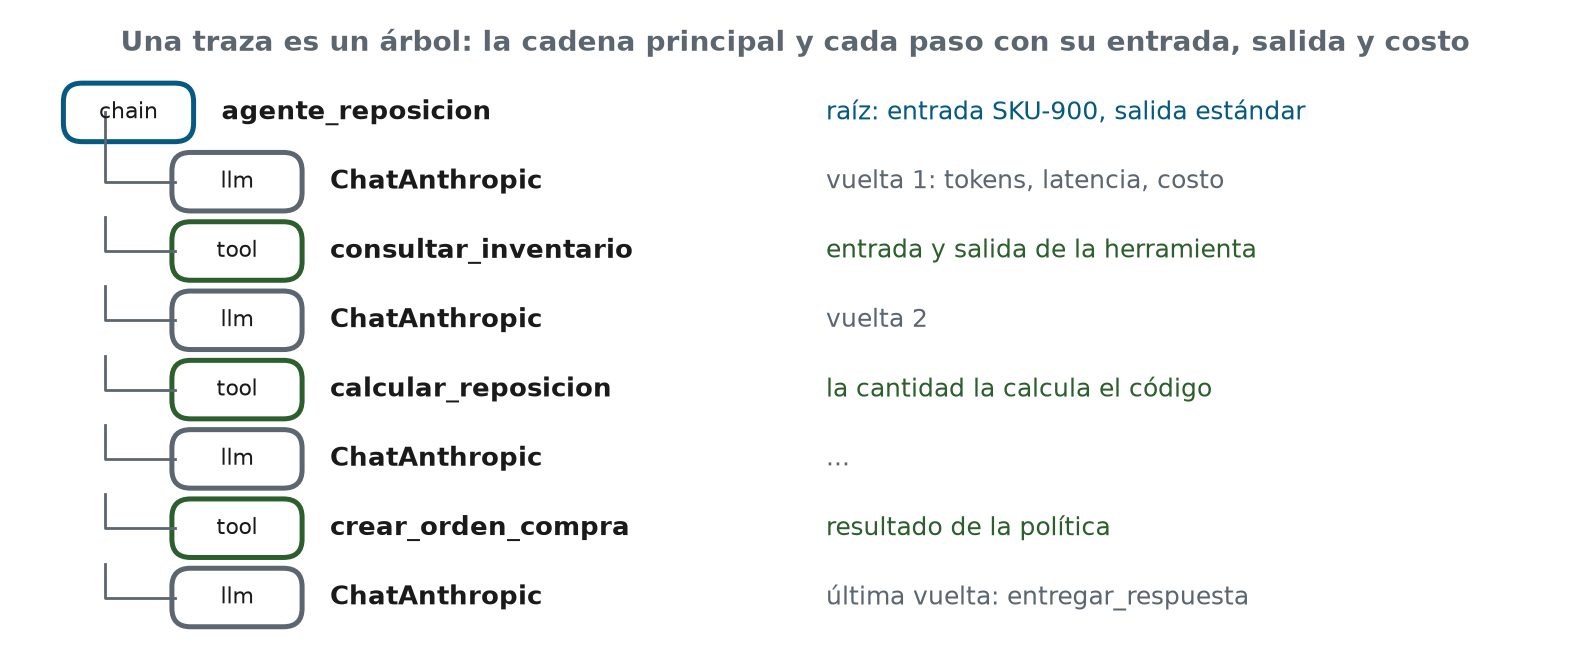

Si las trazas están activas, abre [smith.langchain.com](https://smith.langchain.com), entra a **Tracing** y elige el proyecto `clase-09-agentes`. La traza más reciente se llama `agente_reposicion`. Revisa:

1. **El árbol:** la cadena principal contiene una llamada `ChatAnthropic` por vuelta del loop y, entre ellas, cada herramienta.
2. **Entradas y salidas:** haz clic en `calcular_reposicion` y compara la cantidad con la orden creada.
3. **Latencia y tokens:** la columna de la derecha muestra cuánto tardó y cuánto costó cada paso.
4. **Etiquetas:** la traza lleva la etiqueta `clase-09`; sirve para filtrar.

La interfaz web no es la única forma de leer una traza. El cliente de LangSmith la entrega como datos. Eso permite construir alertas y reportes: por ejemplo, avisar si una revisión supera los diez segundos.

In [11]:
# Misión 2f: leer la misma traza desde el código
def leer_traza(run_id, intentos=10):
    get_cached_client().flush()   # envía las trazas pendientes
    for _ in range(intentos):
        try:
            run = Client().read_run(run_id, load_child_runs=True)
            if run.end_time and run.child_runs:
                return run
        except LangSmithNotFoundError:
            pass
        time.sleep(2)   # LangSmith procesa la traza unos segundos después de recibirla
    return None

def arbol(run, nivel=0):
    segundos = f"{run.latency:.1f} s" if run.latency else ""
    tokens = f"{run.total_tokens:,} tokens" if run.total_tokens else ""
    print(f"{'    ' * nivel}{run.run_type:6} {run.name:22} {segundos:>7}  {tokens}")
    for hijo in sorted(run.child_runs or [], key=lambda r: r.start_time):
        arbol(hijo, nivel + 1)

if tracing_is_enabled():
    traza = leer_traza(RUN_ID)
    if traza:
        arbol(traza)
        print(f"\nCosto total estimado por LangSmith: USD {traza.total_cost or 0:.5f}")
    else:
        print("La traza aún no está disponible. Ejecuta esta celda de nuevo en unos segundos.")
else:
    print("Trazas apagadas: esta celda necesita LANGSMITH_API_KEY.")

/var/folders/p1/vpgfln0n1_z645h_60n7_9940000gr/T/ipykernel_42296/3084117637.py:6: LangSmithDeprecationWarning: read_run() is deprecated and will be removed after Jan 31, 2027. Use client.runs.retrieve() instead.See https://docs.langchain.com/langsmith/smithdb-sdk-migration-runs#runs-retrieve for the migration guide.
  run = Client().read_run(run_id, load_child_runs=True)


chain  agente_reposicion        6.0 s  24,977 tokens
    llm    ChatAnthropic            2.2 s  5,804 tokens
    tool   consultar_inventario     0.0 s  
    tool   consultar_proveedor      0.0 s  
    llm    ChatAnthropic            0.7 s  6,043 tokens
    tool   calcular_reposicion      0.0 s  
    llm    ChatAnthropic            1.2 s  6,332 tokens
    tool   crear_orden_compra       0.0 s  
    llm    ChatAnthropic            1.9 s  6,798 tokens

Costo total estimado por LangSmith: USD 0.00148


### Un producto que no existe

¿Qué hace el agente si le piden un SKU que no está en el catálogo? Las herramientas responden con error (`is_error`). La instrucción del prompt dice que no invente datos y que escale. Un agente que inventa un stock para completar la tarea es más peligroso que uno que se detiene.

In [12]:
# Misión 2g: el SKU-999 no existe; el agente debe escalar
mostrar(*revisar("SKU-999"))

Pasos: 2
{
  "answer": "No fue posible revisar el SKU-999 porque el sistema de inventario indica que no existe. No se calculó reposición ni se generó orden de compra.",
  "action": "escalado",
  "evidence": [
    "consultar_inventario('SKU-999') devolvió error: 'No existe 'SKU-999'.'",
    "El SKU-999 no aparece en el catálogo proporcionado."
  ],
  "confidence": 0.9,
  "next_step": "Verificar con el área de catálogo si el código SKU-999 es correcto o si debe darse de alta; luego reintentar la revisión de inventario."
}


En la traza, los pasos con error aparecen marcados en rojo. Es la primera señal que revisa un equipo de operaciones.

**Para la puesta en común:** un cliente reclama que el agente compró de más. Con la traza abierta, ¿cómo demuestras qué dato usó y de dónde salió la cantidad? ¿Qué no podrías demostrar sin trazas?

---

## Misión 3: SIMULATE, SAFE y LIVE

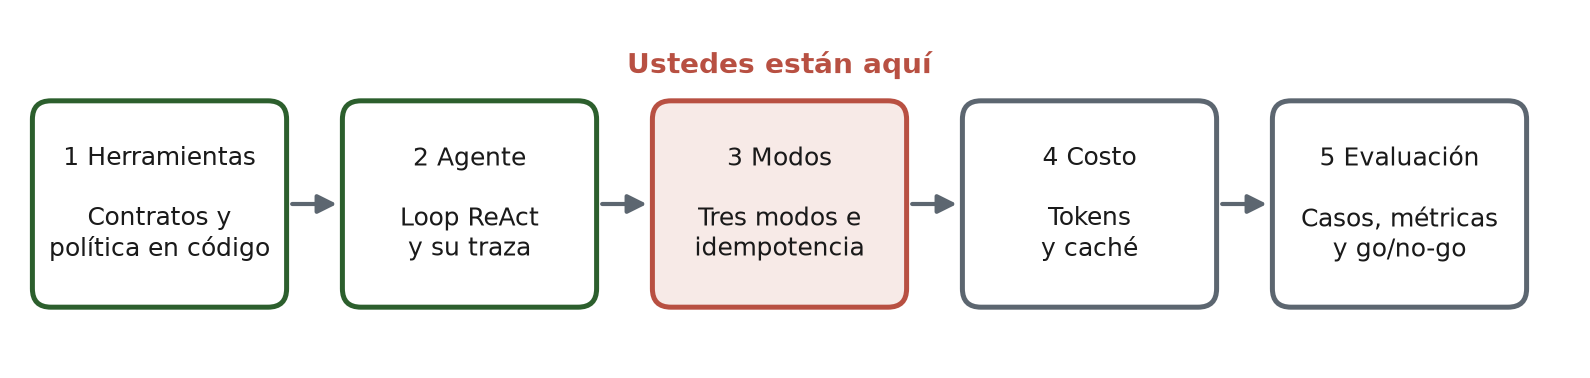

Un agente que escribe en sistemas reales necesita modos de operación:

| Modo | Qué hace `crear_orden_compra` | Cuándo usarlo |
|---|---|---|
| SIMULATE | Informa qué haría y no guarda nada | Pruebas y demos |
| SAFE | Guarda la orden como borrador; un humano la envía | Las primeras semanas en producción |
| LIVE | Envía la orden si la política lo permite | Cuando las métricas lo justifican |

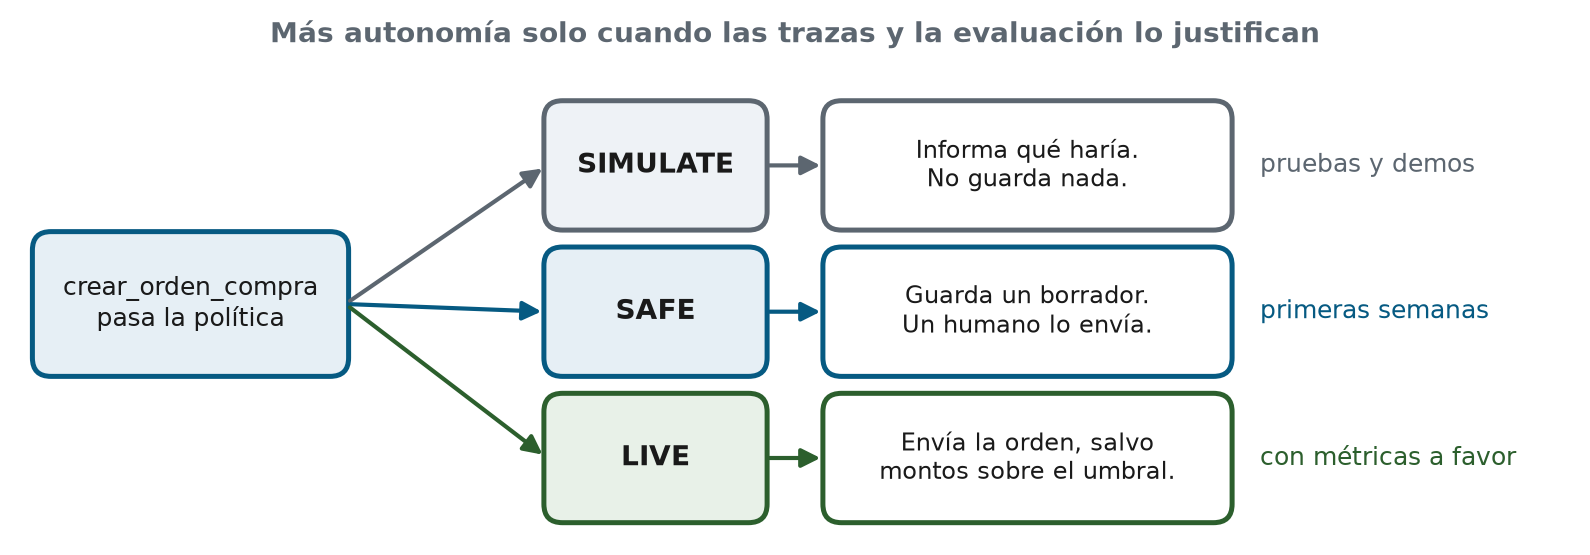

La **idempotencia** evita duplicados: si el agente repite la misma orden, el sistema no la crea dos veces. Importa porque las redes fallan: si la respuesta de la API se pierde, el agente reintenta, y sin idempotencia el proveedor recibiría dos órdenes.

In [13]:
# Misión 3a: el mismo SKU en los tres modos
for MODO in ["SIMULATE", "SAFE", "LIVE"]:
    ORDENES = {}
    salida, pasos = revisar("SKU-900")
    print(f"{MODO:9} -> {salida.action:15} órdenes guardadas: {list(ORDENES.values())}")

SIMULATE  -> orden_simulada  órdenes guardadas: []
SAFE      -> orden_borrador  órdenes guardadas: [{'sku': 'SKU-900', 'cantidad': 470, 'monto': 1175000, 'estado': 'borrador', 'motivo': 'Reposición SKU-900 (Aceite maravilla 1 L): stock 40 unidades, consumo diario 30, cobertura 1,3 días. Horizonte de 14 días más lead time de 3 días (17 días a cubrir). Cantidad sugerida por calcular_reposicion: 470. Proveedor PR-01 (Agrícola Sur) activo.'}]
LIVE      -> orden_enviada   órdenes guardadas: [{'sku': 'SKU-900', 'cantidad': 470, 'monto': 1175000, 'estado': 'enviada', 'motivo': 'Reposición para horizonte de 14 días más lead time de 3 días (17 días a cubrir). Stock actual 40 unidades, consumo diario 30, cobertura 1.3 días. Proveedor PR-01 (Agrícola Sur) activo.'}]


In [14]:
# Misión 3b: idempotencia; la segunda llamada no duplica la orden
print(crear_orden_compra("SKU-900", 470, "Reintento tras un corte de red"))
print("Órdenes:", len(ORDENES))

Sin cambios: la orden SKU-900-470 ya existe en estado enviada.
Órdenes: 1


### La aprobación humana (HITL)

Aun en LIVE, una orden sobre el umbral queda en borrador. Solo un comprador la envía. La función `aprobar_orden` **no** está en `ACCIONES`: el agente no la puede llamar, aunque lo intente.

In [15]:
# Misión 3c: el comprador aprueba el borrador; el agente no puede hacerlo
def aprobar_orden(clave, comprador):
    orden = ORDENES.get(clave)
    if not orden or orden["estado"] != "borrador":
        return f"No hay un borrador {clave} por aprobar."
    orden |= {"estado": "enviada", "aprobada_por": comprador}
    return f"Orden {clave} enviada. Aprobó: {comprador}."

MODO, ORDENES = "LIVE", {}
print(crear_orden_compra("SKU-902", 2_200, "Consumo alto"))
print(ejecutar_herramienta("aprobar_orden", {"clave": "SKU-902-2200", "comprador": "agente"}))   # el agente lo intenta
print(aprobar_orden("SKU-902-2200", "jefa de compras"))
print(ORDENES["SKU-902-2200"])

Orden SKU-902-2200 por $2.420.000 en estado borrador. Requiere la aprobación de un comprador.
('Herramienta aprobar_orden no permitida.', True)
Orden SKU-902-2200 enviada. Aprobó: jefa de compras.
{'sku': 'SKU-902', 'cantidad': 2200, 'monto': 2420000, 'estado': 'enviada', 'motivo': 'Consumo alto', 'aprobada_por': 'jefa de compras'}


**Para la puesta en común:** ¿cuántas semanas dejarías al agente en SAFE antes de pasar a LIVE? ¿Qué métrica de la traza revisarías para decidirlo?

---

## Misión 4: tokens y caché

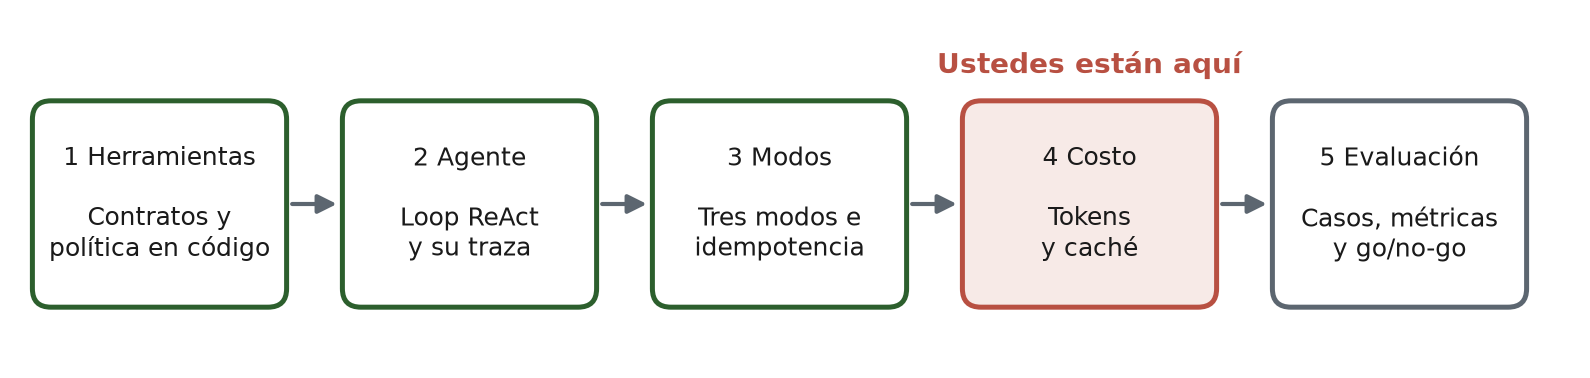

Cada vuelta del loop envía de nuevo el prompt de sistema con el catálogo. La marca `cache_control` guarda ese prefijo en caché: la primera llamada lo escribe y las siguientes lo leen a menor costo. LangSmith muestra los mismos números en cada paso `ChatAnthropic`.

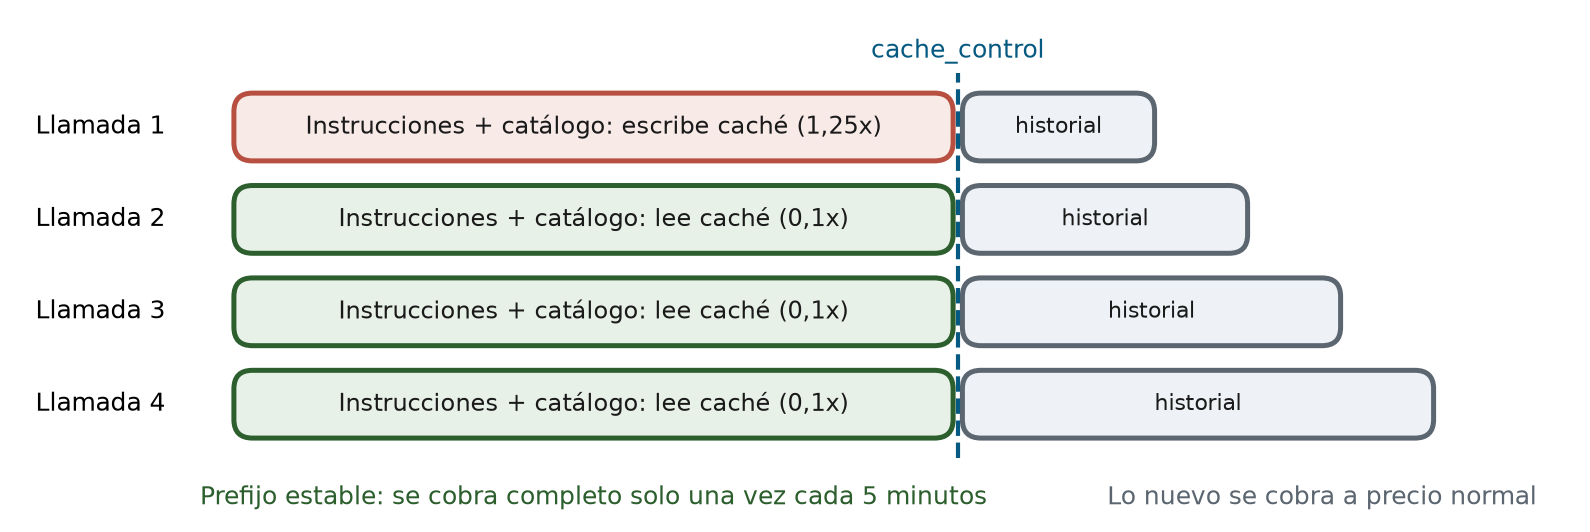

La caché funciona por prefijo: todo lo que está antes de la marca debe ser idéntico entre llamadas. Por eso el catálogo va primero y el historial de la conversación después.

In [16]:
# Misión 4: uso de tokens de dos revisiones seguidas
for campo in USO:
    USO[campo] = 0
MODO = "SAFE"
ORDENES = {}
revisar("SKU-902")
revisar("SKU-903")
for campo, valor in USO.items():
    print(f"{campo:30} {valor:>8,}")
if not hay_clave:
    print("(Modo simulado: no hay tokens que contar)")

input_tokens                      3,568
cache_creation_input_tokens           0
cache_read_input_tokens          38,395
output_tokens                     1,559


### De tokens a dólares

Los tokens se convierten en costo con el precio por millón de tokens (MTok). Usamos los precios de lista de Claude Haiku 5.5 a noviembre de 2026; revisa la [página de precios](https://www.anthropic.com/pricing) antes de usarlos en un presupuesto. La cuenta la hace el código, no el modelo.

In [17]:
# Misión 4b: costo por revisión, con y sin caché, y proyección mensual
PRECIO_MTOK = {"input_tokens": 0.10, "cache_creation_input_tokens": 0.125,   # USD por millón de tokens
               "cache_read_input_tokens": 0.01, "output_tokens": 0.50}

def costo_usd(uso, con_cache=True):
    if not con_cache:   # sin caché, todo el prompt se cobra a precio de entrada normal
        entrada = uso["input_tokens"] + uso["cache_creation_input_tokens"] + uso["cache_read_input_tokens"]
        uso = {"input_tokens": entrada, "output_tokens": uso["output_tokens"]}
    return sum(PRECIO_MTOK[campo] * n / 1_000_000 for campo, n in uso.items())

REVISIONES, DIAS = 2, 30   # la celda anterior revisó dos SKU
for etiqueta, con_cache in [("con caché", True), ("sin caché", False)]:
    por_revision = costo_usd(USO, con_cache) / REVISIONES
    mensual = por_revision * len(CATALOGO) * DIAS   # todo el catálogo, una vez al día
    print(f"{etiqueta}: USD {por_revision:.5f} por revisión, USD {mensual:,.2f} al mes")
if not hay_clave:
    print("(Modo simulado: los costos son cero)")

con caché: USD 0.00076 por revisión, USD 2.37 al mes
sin caché: USD 0.00249 por revisión, USD 7.76 al mes


La proyección supone que la caché sigue viva entre revisiones: dura cinco minutos desde la última lectura. Si el agente revisa los SKU en lote, uno tras otro, el supuesto se cumple.

**Para la puesta en común:** `cache_read_input_tokens` debería superar con creces a `cache_creation_input_tokens`. ¿Por qué el inventario no va en el prompt de sistema junto al catálogo?

---

## Misión 5: evaluación mínima y decisión go/no-go

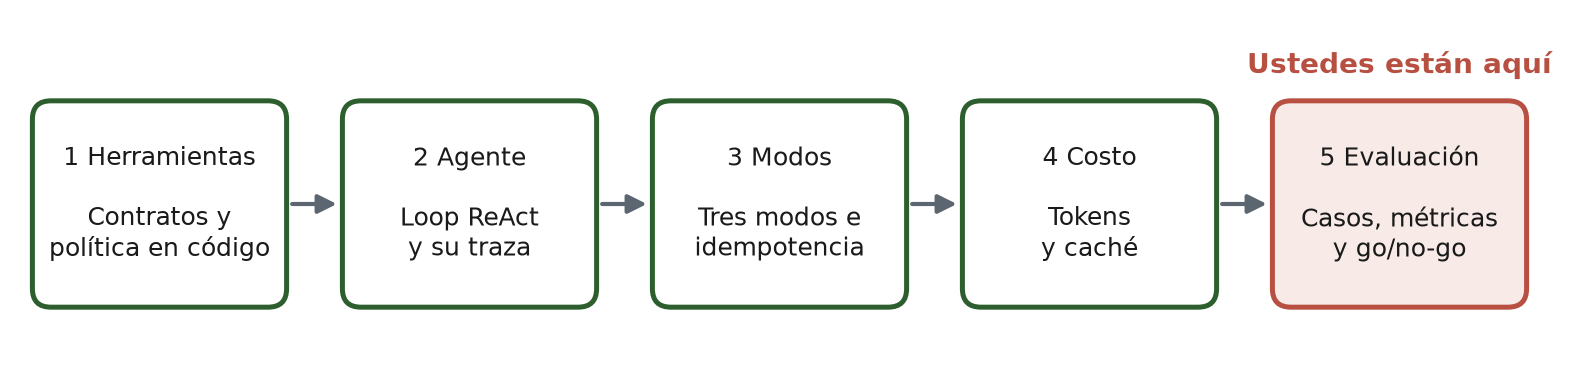

Antes de pasar a LIVE, el agente debe aprobar un set de casos con resultado conocido. Medimos cinco cosas:

1. **Acierto de acción:** la acción final coincide con la esperada.
2. **Cumplimiento de política:** ninguna orden enviada viola la política.
3. **Evidencia:** la respuesta cita al menos dos datos.
4. **Pasos:** cuántas vueltas del loop usó.
5. **Latencia:** cuántos segundos tardó.

Cada caso se envía a LangSmith con la etiqueta `eval` y el nombre del caso como metadato, para filtrarlos después.

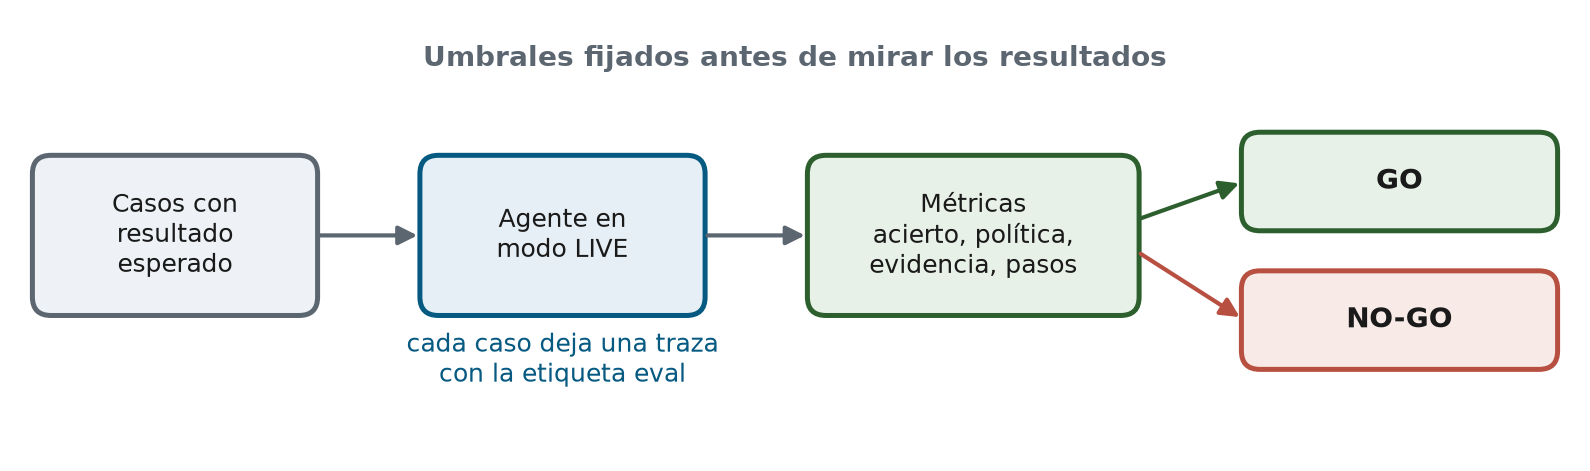

Cada caso cubre un camino distinto del agente: compra normal, proveedor bloqueado, monto sobre el umbral, stock suficiente y producto inexistente.

In [18]:
# Misión 5a: los casos con su resultado esperado
CASOS = [
    {"nombre": "camino feliz", "sku": "SKU-900", "esperado": "orden_enviada"},
    {"nombre": "proveedor bloqueado", "sku": "SKU-901", "esperado": "rechazado"},
    {"nombre": "monto sobre el umbral", "sku": "SKU-902", "esperado": "orden_borrador"},
    {"nombre": "stock suficiente", "sku": "SKU-903", "esperado": "sin_accion"},
    {"nombre": "SKU inexistente", "sku": "SKU-999", "esperado": "escalado"},
]

def cumple_politica():
    """Toda orden enviada pasa la política, y si superaba el umbral, la aprobó un humano."""
    for o in ORDENES.values():
        if o["estado"] != "enviada":
            continue
        bloqueos, requiere_aprobacion = revisar_politica(o["sku"], o["cantidad"])
        if bloqueos or (requiere_aprobacion and not o.get("aprobada_por")):
            return False
    return True

def evaluar(casos):
    filas = []
    for caso in casos:
        inicio = time.perf_counter()
        salida, pasos = revisar(caso["sku"], langsmith_extra={"tags": ["eval"], "metadata": {"caso": caso["nombre"]}})
        filas.append({"caso": caso["nombre"], "acierto": salida.action == caso["esperado"], "accion": salida.action,
                      "politica": cumple_politica(), "evidencia": len(salida.evidence) >= 2,
                      "pasos": pasos, "segundos": round(time.perf_counter() - inicio, 1)})
    return filas

In [19]:
# Misión 5b: correr la evaluación en modo LIVE
MODO = "LIVE"
ORDENES = {}
filas = evaluar(CASOS)
for f in filas:
    print(f"{f['caso']:22} acierto={f['acierto']!s:5} acción={f['accion']:15} política={f['politica']!s:5} "
          f"evidencia={f['evidencia']!s:5} pasos={f['pasos']} {f['segundos']} s")

camino feliz           acierto=True  acción=orden_enviada   política=True  evidencia=True  pasos=4 5.1 s
proveedor bloqueado    acierto=True  acción=rechazado       política=True  evidencia=True  pasos=3 4.1 s
monto sobre el umbral  acierto=True  acción=orden_borrador  política=True  evidencia=True  pasos=4 4.7 s
stock suficiente       acierto=True  acción=sin_accion      política=True  evidencia=True  pasos=3 3.9 s
SKU inexistente        acierto=True  acción=escalado        política=True  evidencia=True  pasos=3 3.8 s


In [20]:
# Misión 5c: la decisión go/no-go, con umbrales fijados antes de mirar los resultados
UMBRAL_ACIERTO = 0.9

def decidir_go(filas):
    acierto = sum(f["acierto"] for f in filas) / len(filas)
    politica = all(f["politica"] for f in filas)
    evidencia = all(f["evidencia"] for f in filas)
    return ("GO" if acierto >= UMBRAL_ACIERTO and politica and evidencia else "NO-GO"), acierto

decision, acierto = decidir_go(filas)
print(f"Acierto: {acierto:.0%}. Política: {all(f['politica'] for f in filas)}. Decisión: {decision}")
get_cached_client().flush()   # envía a LangSmith las trazas pendientes antes de seguir

Acierto: 100%. Política: True. Decisión: GO


### La evaluación como experimento de LangSmith

La tabla anterior vive solo en este notebook. LangSmith guarda los casos como un **dataset** y cada corrida como un **experimento**. Así puedes comparar versiones del prompt o del modelo con los mismos casos, lado a lado, en la pestaña **Datasets & Experiments**.

El evaluador `acierto` recibe la salida del agente y la salida de referencia, y devuelve verdadero o falso.

In [21]:
# Misión 5d: dataset y experimento en LangSmith
DATASET = "clase-09-reposicion"

def objetivo(inputs):
    salida, pasos = revisar(inputs["sku"])
    return {"action": salida.action, "pasos": pasos}

def acierto(outputs, reference_outputs):
    return outputs["action"] == reference_outputs["action"]

if tracing_is_enabled():
    ls = Client()
    if not ls.has_dataset(dataset_name=DATASET):
        ls.create_dataset(DATASET, description="Casos de la misión 5, clase 9")
        ls.create_examples(dataset_name=DATASET,
                           examples=[{"inputs": {"sku": c["sku"]}, "outputs": {"action": c["esperado"]}} for c in CASOS])
    MODO, ORDENES = "LIVE", {}
    resultados = evaluate(objetivo, data=DATASET, evaluators=[acierto], experiment_prefix="clase-09",
                          max_concurrency=1)   # uno a la vez: ORDENES y MODO son estado compartido
    for fila in resultados:
        print(f"{fila['example'].inputs['sku']}  {fila['run'].outputs['action']:15} "
              f"acierto={fila['evaluation_results']['results'][0].score}")
    print("Experimento:", resultados.experiment_name)
else:
    print("Trazas apagadas: el experimento necesita LANGSMITH_API_KEY.")

View the evaluation results for experiment: 'clase-09-750594b5' at:
https://smith.langchain.com/o/f9c4e607-7d71-4492-ace2-c643db686742/datasets/ac2ede9c-e4a9-4fed-adec-9ed0eb9f90fb/compare?selectedSessions=31518498-1a98-43f7-ba9f-5d9e7a37d5e5


SKU-999  escalado        acierto=True
SKU-900  orden_enviada   acierto=True
SKU-902  orden_borrador  acierto=True
SKU-903  sin_accion      acierto=True
SKU-901  rechazado       acierto=True
Experimento: clase-09-750594b5


**Prueba tú:** cambia una línea de `INSTRUCCIONES`, vuelve a ejecutar la misión 2b y esta celda. En LangSmith, selecciona los dos experimentos y usa **Compare**.

**Para la puesta en común:** cinco casos no bastan para producción. ¿Qué casos agregarías? ¿Por qué el cumplimiento de política exige el 100% y el acierto no?

---

## Cierre

Hoy construiste un agente observable:

1. **Herramientas trazables:** cada herramienta es una función con contrato y queda registrada en la traza.
2. **Política en código:** el proveedor bloqueado y el umbral de aprobación no dependen del prompt.
3. **Salida estándar:** respuesta, acción, evidencia, confianza y siguiente paso, validados con Pydantic.
4. **Trazas legibles:** el árbol se lee en la web o desde el código, y los errores quedan a la vista.
5. **Modos, idempotencia y HITL:** SIMULATE, SAFE y LIVE controlan los efectos secundarios; la clave evita duplicados; un humano aprueba los montos altos.
6. **Costo medido:** los tokens de cada traza se convierten en dólares, y la caché reduce el costo del prompt fijo.
7. **Evaluación:** un dataset de casos y un experimento en LangSmith deciden si el agente pasa a producción.

Un agente sin trazas no se puede auditar, y un agente sin evaluación no se puede promover a LIVE.